# 31 — Training-budget convergence of the System I production posterior

Fixed controller law (2026-11-08); warm-start protocol chosen by notebook 29
(`results/29fx_selection.json`). This notebook refuses to start if that selection is flagged.

**Design.** One 160k simulation bank under the chosen protocol, simulated once. Budgets
5k, 10k, 20k, 40k, 80k, 160k × seeds 0–4 (nb29 measured ~20 s per 5k training run). Seed *s* trains on the first *N* rows
of its own permutation of the bank: nested across budgets for a fixed seed, different data
across seeds. A held-out test set (1000 SBC draws + 6 scenarios × 50 reps) from a reserved
seed. Each (N, seed) posterior and the 5-seed ensemble are scored with the nb29 suite.

## Convergence rule — fixed before results

Step N_k → N_{k+1} is **converged** if, for the ensemble at both budgets:
(a) |ΔCorr(α,β)| < 0.05 at each of Sc1, Sc2, Sc3, Sc4, Sc7 (Sc5 reported, not gated);
(b) |Δ 90% marginal coverage| < 0.02 for α and β;
(c) |ΔTARP deviation| < 0.01;
(d) at N_{k+1}: marginal KS p ≥ 0.01 for α and β on the **interior** SBC subset (true θ at
least 5% of the prior width from every edge), and TARP KS p ≥ 0.01 on the full set.
Full-set KS is reported alongside. *Amended after nb29, before any nb31 result:* in nb29 the
full-set α KS failed for every protocol at 5k while 90% coverage was ≈0.91; the interior gate
separates estimator bias from prior-edge truncation.

**Production budget** = N_{k+1} of the first converged step. If none converges: flag and review.
**Ensemble vs single seed**: ensemble if its TARP deviation ≤ the median single-seed TARP
deviation at that budget, else the single seed with the lowest TARP deviation.
Result: `results/31_production.json`, loaded downstream with `load_production_posterior()`.

**Running this notebook.** Execute top to bottom from `notebooks/system_I`. Training is the
long part (seconds at 5k, of order 10–30 min per seed at 160k). With `PARALLEL_TRAINING`,
seed groups train in subprocesses launched from this folder. Re-running resumes.


> **Sensor model: N3** (N3: sigma_C=0.01 mol/L, sigma_T=0.2 K, sigma_Tc=0.2 K, sigma_Qc=2.0 L/min). Budget study under the production sensor model adopted
> on 2026-11-09 after notebook 33. The N0 study is `31_budget_convergence.ipynb` (kept for the
> SI). Outputs carry the prefix `31_N3_`; the production record is `results/31_N3_production.json`.
> **Decision rule: v2 is pre-set here** (adopted by the user on 2026-11-08, before any N3
> result): Sc7 excluded from the gate, < 10% change in posterior sd, persistence; if no step
> qualifies, the largest budget passing calibration. Section 4 still prints the v1 outcome for
> the record.

In [1]:
import json, os, sys, time, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_protocols, ws_eval, system_I_config, nb31_budget_convergence
for _m in (system_I_config, ws_protocols, ws_eval, nb31_budget_convergence):
    importlib.reload(_m)
B = nb31_budget_convergence
assert B.SENSOR == "N3", B.SENSOR
R, FIGS = ROOT / "results", ROOT / "figures"

# ---- run switches -----------------------------------------------------------------
BUDGETS = B.DEFAULT_BUDGETS          # add 80_000 only if the decision below asks for it
PARALLEL_TRAINING = True
SEED_GROUPS = [[0, 1], [2, 3], [4]]  # one subprocess per group
THREADS = 3
T0 = time.time()

PROTOCOL = B.protocol()              # stops here if nb29's selection is missing or flagged
print("protocol from nb29:", PROTOCOL)

protocol from nb29: P2


## 0. Scenario catalogue used for the test set
The test set's scenario grid is read from `cstr_sbi.scenarios.SCENARIO_CONFIGS`. nb29 found
Sc5's β on the prior edge and Sc2 saturated; settle any catalogue change **before** section 1
(the test set is simulated once and cached).

In [2]:
from cstr_sbi.scenarios import SCENARIO_CONFIGS
import ws_eval as we
display(pd.DataFrame([{"scenario": k, "alpha": SCENARIO_CONFIGS[k].alpha, "beta": SCENARIO_CONFIGS[k].beta,
                       "drift_T": SCENARIO_CONFIGS[k].drift_T,
                       "on_prior_edge": bool(np.isclose([SCENARIO_CONFIGS[k].alpha, SCENARIO_CONFIGS[k].beta],
                                                        np.r_[we.LO, we.HI].reshape(2, 2)).any())}
                      for k in we.EVAL_SCENARIOS]))

,scenario,alpha,beta,drift_T,on_prior_edge
0,Sc1_closed_healthy,1.00,1.00,0.0,False
1,Sc2_closed_fouling,1.00,0.85,0.0,False
2,Sc3_closed_decay,0.70,1.00,0.0,False
3,Sc4_closed_combined,0.85,0.85,0.0,False
4,Sc5_closed_saturated,1.00,0.50,0.0,False
5,Sc7_closed_drift,1.00,0.85,2.0,False


## 1. Simulation bank (160k) and held-out test set

In [3]:
B.stage_bank(PROTOCOL)
B.stage_test(PROTOCOL)

## 2. Train budgets × seeds

In [4]:
budgets_arg = ",".join(str(b) for b in BUDGETS)
if PARALLEL_TRAINING:
    procs = []
    for g in SEED_GROUPS:
        seeds = ",".join(str(s) for s in g)
        log = open(R / f"{B.TAG}_train_seeds{seeds.replace(',', '_')}.log", "w")
        procs.append(subprocess.Popen(
            [sys.executable, str(ROOT / "scripts" / "nb31_budget_convergence.py"), "train",
             "--protocol", PROTOCOL, "--budgets", budgets_arg, "--seeds", seeds, "--threads", str(THREADS)],
            cwd=NB_DIR, stdout=log, stderr=subprocess.STDOUT))
    codes = [p.wait() for p in procs]
    assert all(c == 0 for c in codes), f"training subprocess failed: {codes} (see results/31_train_*.log)"
else:
    B.stage_train(PROTOCOL, BUDGETS, B.SEEDS, THREADS)
print(sorted(f.name for f in B.OUT.glob("post_*.pkl")))

['post_P2_S1_base_est_n10000_s0.pkl', 'post_P2_S1_base_est_n10000_s1.pkl', 'post_P2_S1_base_est_n10000_s2.pkl', 'post_P2_S1_base_est_n10000_s3.pkl', 'post_P2_S1_base_est_n10000_s4.pkl', 'post_P2_S1_base_est_n160000_s0.pkl', 'post_P2_S1_base_est_n160000_s1.pkl', 'post_P2_S1_base_est_n160000_s2.pkl', 'post_P2_S1_base_est_n160000_s3.pkl', 'post_P2_S1_base_est_n160000_s4.pkl', 'post_P2_S1_base_est_n20000_s0.pkl', 'post_P2_S1_base_est_n20000_s1.pkl', 'post_P2_S1_base_est_n20000_s2.pkl', 'post_P2_S1_base_est_n20000_s3.pkl', 'post_P2_S1_base_est_n20000_s4.pkl', 'post_P2_S1_base_est_n40000_s0.pkl', 'post_P2_S1_base_est_n40000_s1.pkl', 'post_P2_S1_base_est_n40000_s2.pkl', 'post_P2_S1_base_est_n40000_s3.pkl', 'post_P2_S1_base_est_n40000_s4.pkl', 'post_P2_S1_base_est_n5000_s0.pkl', 'post_P2_S1_base_est_n5000_s1.pkl', 'post_P2_S1_base_est_n5000_s2.pkl', 'post_P2_S1_base_est_n5000_s3.pkl', 'post_P2_S1_base_est_n5000_s4.pkl', 'post_P2_S1_base_est_n80000_s0.pkl', 'post_P2_S1_base_est_n80000_s1.pkl', 

## 3. Evaluate every (budget, seed) posterior and the ensembles

In [5]:
B.stage_eval(PROTOCOL)

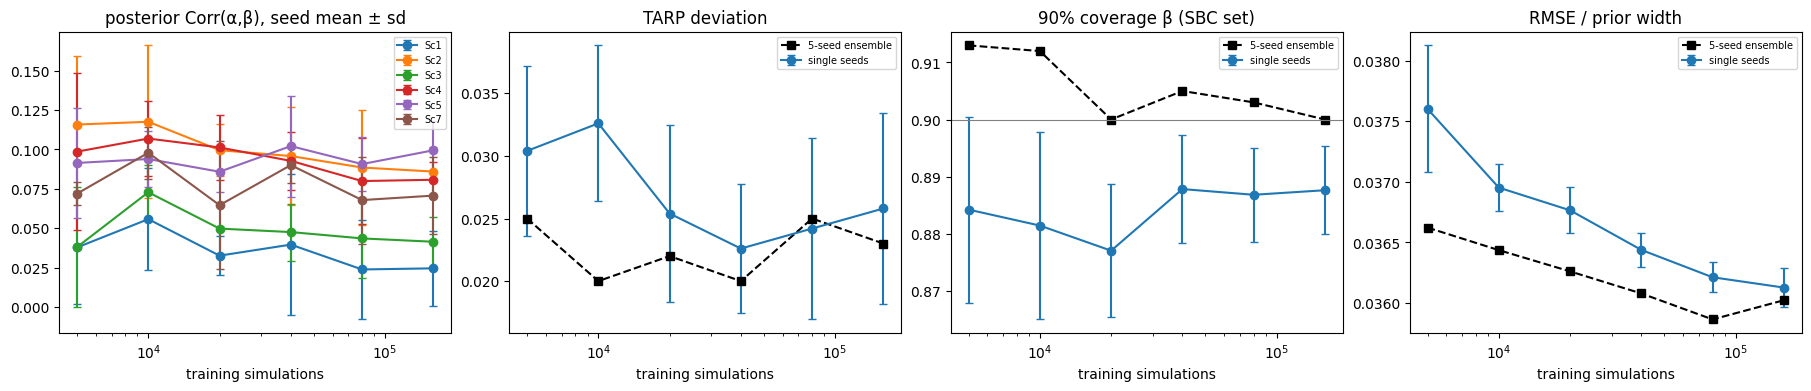

,ks_p_a,ks_p_b,ks_p_a_interior,ks_p_b_interior,tarp_ks_p,tarp_dev,cov90_a,cov90_b,rmse_norm,macro_f1,leak_sbc_mean,corr_Sc1,corr_Sc2,corr_Sc3,corr_Sc4,corr_Sc7
budget,,,,,,,,,,,,,,,,
5000,0.990,0.272,0.861,0.040,0.551,0.025,0.902,0.913,0.037,0.857,0.026,0.043,0.108,0.027,0.105,0.121
10000,0.728,0.482,0.476,0.695,0.710,0.020,0.902,0.912,0.036,0.849,0.022,0.053,0.088,0.067,0.085,0.105
20000,0.864,0.956,0.486,0.313,0.710,0.022,0.906,0.900,0.036,0.887,0.018,0.032,0.103,0.039,0.107,0.111
40000,0.944,0.407,0.879,0.080,0.762,0.020,0.895,0.905,0.036,0.862,0.008,0.044,0.083,0.043,0.090,0.066
80000,0.873,0.272,0.636,0.813,0.452,0.025,0.907,0.903,0.036,0.886,0.008,0.041,0.092,0.050,0.081,0.002
160000,0.419,0.759,0.216,0.188,0.500,0.023,0.899,0.900,0.036,0.869,0.007,0.032,0.075,0.045,0.075,0.119


In [6]:
m = pd.read_csv(R / f"{B.TAG}_metrics.csv"); m["member"] = m["member"].astype(str)
ens, single = m[m.member == "ensemble"].sort_values("budget"), m[m.member != "ensemble"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), constrained_layout=True)
for sc in ["Sc1", "Sc2", "Sc3", "Sc4", "Sc5", "Sc7"]:
    g = single.groupby("budget")[f"corr_{sc}"]
    axes[0].errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, label=sc)
axes[0].set_title("posterior Corr(α,β), seed mean ± sd"); axes[0].legend(fontsize=7)
for k, ax, t in [("tarp_dev", axes[1], "TARP deviation"), ("cov90_b", axes[2], "90% coverage β (SBC set)"),
                 ("rmse_norm", axes[3], "RMSE / prior width")]:
    g = single.groupby("budget")[k]
    ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, label="single seeds")
    ax.plot(ens.budget, ens[k], "k--s", label="5-seed ensemble"); ax.set_title(t); ax.legend(fontsize=7)
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("training simulations")
axes[2].axhline(0.9, color="grey", lw=0.8)
fig.savefig(FIGS / f"{B.TAG}_budget_convergence.png", dpi=150); plt.show()
display(ens.set_index("budget")[["ks_p_a", "ks_p_b", "ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p", "tarp_dev", "cov90_a", "cov90_b",
                                 "rmse_norm", "macro_f1", "leak_sbc_mean",
                                 "corr_Sc1", "corr_Sc2", "corr_Sc3", "corr_Sc4", "corr_Sc7"]].round(3))

### Per-scenario classification accuracy and β coverage (ensemble)
Fraction of the 50 test windows per scenario assigned to the true fault class (threshold
0.90), and the 90% coverage of β at the truth. Sc2 (β = 0.85) sits at the midpoint of the
unsaturated fouling band, 0.05 below the threshold, so its accuracy is expected below ~100%.

In [7]:
scn = pd.read_csv(R / f"{B.TAG}_scenarios.csv"); scn["member"] = scn["member"].astype(str)
e_sc = scn[scn.member == "ensemble"]
display(e_sc.pivot_table(index="scenario", columns="budget", values="class_acc").round(3))
display(e_sc.pivot_table(index="scenario", columns="budget", values="cov90_truth_b").round(3))
display(e_sc.pivot_table(index="scenario", columns="budget", values="beta_hat").round(3))

budget,5000,10000,20000,40000,80000,160000
scenario,,,,,,
Sc1_closed_healthy,0.98,0.98,0.98,0.98,0.98,0.98
Sc2_closed_fouling,1.00,1.00,1.00,1.00,1.00,1.00
Sc3_closed_decay,1.00,1.00,1.00,1.00,1.00,1.00
Sc4_closed_combined,0.80,0.78,0.78,0.80,0.80,0.76
Sc5_closed_saturated,0.96,0.96,0.96,0.96,0.98,0.98
Sc7_closed_drift,0.28,0.24,0.56,0.32,0.50,0.42


budget,5000,10000,20000,40000,80000,160000
scenario,,,,,,
Sc1_closed_healthy,0.98,0.96,0.94,0.92,0.92,0.90
Sc2_closed_fouling,0.98,0.96,0.98,0.94,0.96,0.94
Sc3_closed_decay,0.96,0.90,0.92,0.92,0.90,0.88
Sc4_closed_combined,0.96,0.94,0.92,0.92,0.92,0.88
Sc5_closed_saturated,1.00,0.94,0.92,0.98,0.92,0.96
Sc7_closed_drift,0.00,0.00,0.00,0.00,0.00,0.00


budget,5000,10000,20000,40000,80000,160000
scenario,,,,,,
Sc1_closed_healthy,1.002,1.003,1.003,1.003,1.001,1.002
Sc2_closed_fouling,0.847,0.846,0.848,0.848,0.845,0.847
Sc3_closed_decay,1.004,1.002,1.003,1.003,1.001,1.003
Sc4_closed_combined,0.853,0.851,0.852,0.851,0.849,0.851
Sc5_closed_saturated,0.498,0.495,0.495,0.499,0.498,0.498
Sc7_closed_drift,0.491,0.482,0.477,0.468,0.464,0.467


### α calibration and efficiency against the Cramér–Rao bound
Full-set vs interior α SBC KS by budget, and the posterior sd at each scenario divided by the
29-D-summary Cramér–Rao bound from nb29 E2 (same protocol). A ratio well above 1 means the
estimator is not yet extracting the information in the summaries; it should approach ~1 as the
budget grows (exactly 1 only if the summaries' likelihood were Gaussian).

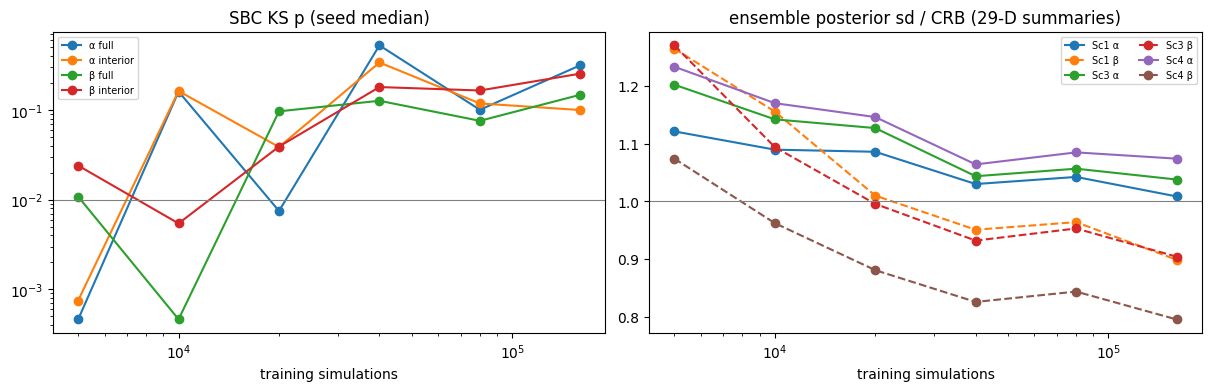

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for k, lab in [("ks_p_a", "α full"), ("ks_p_a_interior", "α interior"), ("ks_p_b", "β full"), ("ks_p_b_interior", "β interior")]:
    g = single.groupby("budget")[k].median()
    axes[0].plot(g.index, g.values, "o-", label=lab)
axes[0].axhline(0.01, color="grey", lw=0.8); axes[0].set_yscale("log"); axes[0].set_xscale("log")
axes[0].set_title("SBC KS p (seed median)"); axes[0].legend(fontsize=7); axes[0].set_xlabel("training simulations")
crb = pd.read_csv(R / f"{B.E2_TAG}_e2_fim.csv")
crb = crb[(crb.protocol == PROTOCOL) & (crb.representation == "summaries_fullcov")]
pts = {"Sc1": (1.0, 1.0), "Sc2": (1.0, 0.7), "Sc3": (0.7, 1.0), "Sc4": (0.85, 0.85)}
for sc, (a, b) in pts.items():
    cfg = [k for k in we.EVAL_SCENARIOS if k.startswith(sc + "_")][0]
    if not (np.isclose(SCENARIO_CONFIGS[cfg].alpha, a) and np.isclose(SCENARIO_CONFIGS[cfg].beta, b)):
        continue            # catalogue changed since nb29: no matching CRB point
    c = crb[crb.point == sc].iloc[0]
    for par, col, cr, ls in [("α", f"sda_{sc}", c.crb_sd_a, "-"), ("β", f"sdb_{sc}", c.crb_sd_b, "--")]:
        if col in ens:
            axes[1].plot(ens.budget, ens[col] / cr, "o" + ls, label=f"{sc} {par}")
axes[1].axhline(1, color="grey", lw=0.8); axes[1].set_xscale("log"); axes[1].set_xlabel("training simulations")
axes[1].set_title("ensemble posterior sd / CRB (29-D summaries)"); axes[1].legend(fontsize=7, ncol=2)
fig.savefig(FIGS / f"{B.TAG}_alpha_calibration_efficiency.png", dpi=150); plt.show()

## 4. Decision (applies the pre-set rule)

In [9]:
B.stage_decide(PROTOCOL)
res = json.loads((R / f"{B.TAG}_production.json").read_text())
display(pd.DataFrame(res["steps"]).drop(columns=["dcorr"]))
print({k: v for k, v in res.items() if k != "steps"})
if res["flag"]:
    print("FLAG:", res["flag"])

{'from': 5000, 'to': 10000, 'max_dcorr': 0.039856895958757896, 'dcorr': {'Sc1': 0.009347303536711801, 'Sc2': 0.020335421790825495, 'Sc3': 0.039856895958757896, 'Sc4': 0.020110146567972595, 'Sc7': 0.0160300842338401}, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'ks_a_full': 0.7275769930339235, 'ks_b_full': 0.4819281692636782, 'ks_a_interior': 0.4757444164057105, 'ks_b_interior': 0.6947040349521653, 'converged': True}
{'from': 10000, 'to': 20000, 'max_dcorr': 0.028064814140113498, 'dcorr': {'Sc1': 0.0206773472888315, 'Sc2': 0.015323589088155995, 'Sc3': 0.028064814140113498, 'Sc4': 0.021798462540157604, 'Sc7': 0.0059298309896164}, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'ks_a_full': 0.8641981829129177, 'ks_b_full': 0.9560777667987014, 'ks_a_interior': 0.485766220957188, 'ks_b_interior': 0.3133209360127633, 'converged': True}
{'from': 20000, 'to': 40000, 'max_dcorr': 0.045074690038609797, 'dcorr': {'Sc1': 0.012196718299172703, 'Sc2': 0.0196762212

,from,to,max_dcorr,a_corr,b_cov,c_tarp,d_calib,ks_a_full,ks_b_full,ks_a_interior,ks_b_interior,converged
0,5000,10000,0.039857,True,True,True,True,0.727577,0.481928,0.475744,0.694704,True
1,10000,20000,0.028065,True,True,True,True,0.864198,0.956078,0.485766,0.313321,True
2,20000,40000,0.045075,True,True,True,True,0.944364,0.407493,0.879227,0.080353,True
3,40000,80000,0.063738,False,True,True,True,0.873199,0.272392,0.636169,0.812718,False
4,80000,160000,0.116942,False,True,True,True,0.419414,0.758863,0.215873,0.188361,False


{'protocol': 'P2', 'production_budget': 10000, 'use_ensemble': True, 'members': ['/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget_N3/post_P2_S1_base_est_n10000_s0.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget_N3/post_P2_S1_base_est_n10000_s1.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget_N3/post_P2_S1_base_est_n10000_s2.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget_N3/post_P2_S1_base_est_n10000_s3.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget_N3/post_P2_S1_base_est_n10000_s4.pkl'], 'flag': None, 'rule': 'see docstring of scripts/nb31_budget_convergence.py (fixed before results)', 'sensor_model': 'N3', 'summary_set': 'S1_base_est'}


## 4b. Decision under the pre-set rule v2 (N3)
Rule v2 is the pre-set rule for this study (see the note at the top). If no budget passes
calibration (d), the record is FLAGGED and the pipeline must stop for user review.

In [10]:
res_v2 = B.stage_decide_amended(
    PROTOCOL, approve=True,
    approved_by="pre-set rule v2 (adopted by the user on 2026-11-08 for all subsequent budget studies)",
    reason="N3 production budget study; v2 fixed before any N3 result")
display(pd.DataFrame(res_v2["rule_v2_steps"]))
print("production:", res_v2["production_budget"], "ensemble" if res_v2["use_ensemble"] else "single",
      "| v1 would have chosen:", res_v2["rule_v1_choice"], "| sensor model:", res_v2["sensor_model"])
if res_v2.get("flag"):
    raise RuntimeError("STOP: " + res_v2["flag"])

{'from': 5000, 'to': 10000, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'e_precision': False, 'converged': False, 'max_dcorr': 0.04, 'max_rel_dsd': 0.139, 'worst_sd': 'b_Sc3'}
{'from': 10000, 'to': 20000, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'e_precision': False, 'converged': False, 'max_dcorr': 0.028, 'max_rel_dsd': 0.126, 'worst_sd': 'b_Sc1'}
{'from': 20000, 'to': 40000, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'e_precision': True, 'converged': True, 'max_dcorr': 0.02, 'max_rel_dsd': 0.074, 'worst_sd': 'a_Sc3'}
{'from': 40000, 'to': 80000, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'e_precision': True, 'converged': True, 'max_dcorr': 0.009, 'max_rel_dsd': 0.023, 'worst_sd': 'a_Sc2'}
{'from': 80000, 'to': 160000, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'e_precision': True, 'converged': True, 'max_dcorr': 0.016, 'max_rel_dsd': 0.068, 'worst_sd': 'b_Sc1'}
v1 choice: 10000 |

,from,to,a_corr,b_cov,c_tarp,d_calib,e_precision,converged,max_dcorr,max_rel_dsd,worst_sd
0,5000,10000,True,True,True,True,False,False,0.039857,0.138638,b_Sc3
1,10000,20000,True,True,True,True,False,False,0.028065,0.125914,b_Sc1
2,20000,40000,True,True,True,True,True,True,0.019676,0.073953,a_Sc3
3,40000,80000,True,True,True,True,True,True,0.008847,0.022972,a_Sc2
4,80000,160000,True,True,True,True,True,True,0.016421,0.067599,b_Sc1


production: 40000 single | v1 would have chosen: 10000 | sensor model: N3


## 5. Smoke test of the production posterior as downstream notebooks will load it

In [11]:
import torch
post, info = B.load_production_posterior()
test = we.load_npz(B.OUT / f"test_{B._tok(PROTOCOL)}.npz")
x = test["x_sc"][test["sc_name"] == "Sc4_closed_combined"][:1]
s = post.sample((5000,), x=torch.as_tensor(x[0], dtype=torch.float32),
                show_progress_bars=False, reject_outside_prior=False).detach().numpy()
print(info["protocol"], info["production_budget"], "ensemble" if info["use_ensemble"] else "single",
      "| Sc4 mean", s.mean(0).round(3), "corr", round(float(np.corrcoef(s.T)[0, 1]), 3))
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")

P2 40000 single | Sc4 mean [0.927 0.854] corr 0.09
notebook wall time 0.1 min


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2279.)
  outputs, _ = torch.triangular_solve(


## 6. Interpretation (N3 + P2 + S1) — written 2026-11-09, amended the same day (rule v2.1)

**Result.** Under the production set-up (sensor model N3, protocol P2, summary set S1) the amortised posterior is calibrated at every budget from 5k to 160k simulations and reaches the information limit of the production summaries by 40k. The deployed posterior is the **40,000-simulation, 5-seed ensemble** (N0: 160,000 simulations, 5-seed ensemble): rule v2 finds the first persistently converged step at 20k → 40k, and the amended rule v2.1 (below) takes the ensemble as the deployed object. This supports the "reliable" half of the paper (calibrated, at the information limit, correct diagnosis for faults the sensors can resolve); the limitations are stated in 4.

**1. Budget and rule; the amendment v2.1.** Steps 5k → 10k and 10k → 20k fail the precision criterion (largest relative change of a posterior sd 0.139 and 0.126, gate 0.10); 20k → 40k converges (0.074; largest |ΔCorr(α, β)| 0.020), and 40k → 80k (0.023) and 80k → 160k (0.068) stay converged, so the production budget is 40k. The original rule v1 would have chosen 10k; the amended rule v2 was adopted on 2026-11-08, before any N3 result. *Single seed or ensemble.* Rules v1 and v2 deployed the ensemble if its TARP deviation was no larger than the median single member's, otherwise the member with the lowest TARP deviation. At 40k both are 0.0200, so v2 deployed **seed 3 (0.018)**, whose interior β marginal KS p is 0.00005 (quoted as 0.0001 in the amendment record): it fails the calibration criterion (d) that the rule itself requires, because (d) is checked on the ensemble and then a single member is deployed without re-checking. The tie-break also compared two numbers that differ by far less than the sampling noise of the TARP deviation (about 0.043, noted in the rule). **On 2026-11-09, after seeing the results, the user amended the rule (v2.1, a dated post-results amendment recorded in `31_N3_production.json` next to the v2 choice):** *the deployed posterior must itself pass the calibration test (d) at the chosen budget; use the ensemble whenever it does, otherwise the passing member with the lowest TARP deviation, and flag if none passes.* It is a general principle, not a choice of seed; under N0 it gives the same choice as before (the 160k ensemble passes (d); verified from `31_metrics.csv`, the N0 record is not rewritten). At 40k the ensemble passes (d) (interior KS p α 0.879, β 0.080, TARP KS p 0.762), and so do members 1, 2 and 4 (β interior KS p 0.181, 0.413, 0.363); members 0 and 3 fail on β (0.003, 0.00005); all five members pass TARP (KS p 0.17–0.81).

**2. Calibration (the "reliable" half).** Ensemble, all budgets: interior marginal KS p 0.22–0.88 for α and 0.04–0.81 for β (5k: 0.861 / 0.040; 40k: 0.879 / 0.080), full-set KS p 0.42–0.99 (α) and 0.27–0.96 (β), TARP KS p 0.45–0.76 (deviation 0.020–0.025), 90% coverage 0.895–0.907 (α) and 0.900–0.913 (β). Under N0 the α interior test was borderline even at 160k (interior KS p 0.012 at 40k, 0.024 at 160k); here α passes comfortably at every budget. The same-protocol, same-test-set comparison of S0 and S1 is notebook 03 §10b (20k: TARP KS p 0.0056 → 0.048, interior α 0.128 → 0.652); notebook 33's N3/S0 ensemble at 40k (3 seeds, P1b, its own test set, so protocol and test set differ) had an interior α KS p of 0.000, consistent with, but not a clean measurement of, the gain from S1. *Lesson for the practitioner checklist:* calibration is a property of the budget and the ensemble more than of an individual seed (2 of the 5 single members at 40k fail the β marginal test while all five pass TARP), so joint calibration (SBC and TARP) has to be checked on the exact posterior that is deployed.

**3. Precision against the information limit (production feature set S1, `03s_N3_fim.csv`, protocol P2).** The reference is the Cramér–Rao bound of the production summary set; the raw-trajectory bound is not used, because under N3 its Ledoit–Wolf version is *looser* than the summary bound for β (0.031 against 0.014–0.016 at Sc1), which an exact bound cannot be (shrinkage loss when T is precise). Posterior sd divided by the S1 bound (S0 bound in brackets, for comparison only):

| | α Sc1 / Sc3 / Sc4 | β Sc1 / Sc3 / Sc4 |
|---|---|---|
| **deployed: 40k ensemble** | 0.98 / 1.00 / 1.02 | 1.04 / 1.01 / 0.92 (0.95 / 0.94 / 0.83) |
| 160k ensemble | 0.96 / 0.99 / 1.03 | 0.98 / 0.98 / 0.88 (0.90 / 0.91 / 0.80) |
| 20k ensemble | 1.04 / 1.08 / 1.10 | 1.10 / 1.08 / 0.98 (1.01 / 1.00 / 0.88) |
| former v2 choice, 40k seed 3 | 0.98 / 1.01 / 1.02 | 1.02 / 0.99 / 0.85 (0.93 / 0.92 / 0.77) |

At 40k the ensemble posterior sd equals the S1 bound within 2% for α and within 4% for β at Sc1 and Sc3; the estimator gap that was still open at 20k (4–10% above the bound) has closed. At Sc4 the β ratio is 0.85–0.92, below 1: the posterior is narrower than the local Gaussian bound there, possible because the bound is local and Gaussian while the posterior is truncated by the prior and not Gaussian; I have not tested this explanation. The efficiency printed in section 4b and plotted above uses the 29-summary (S0) bound; relative to S1's own bound the β ratios are 0.85–1.04. Absolute precision (40k ensemble, per scenario): α sd 0.027–0.064 (0.052 at Sc2, 0.027 at Sc3, 0.039 at Sc4), β sd 0.014–0.024 (0.014 at Sc2 and Sc4); N0 had α sd 0.002–0.003 and β sd 0.027–0.028 at Sc4, so realistic sensors make α about 15× less precise and β about 2× more precise (the sensor-ladder result of notebook 33, not a setback of the estimator).

**4. Diagnosis per scenario (class accuracy, threshold 0.90; 40k ensemble, 50 windows per scenario).** Sc1 0.98, Sc2 1.00, Sc3 1.00, **Sc4 0.80 on this fixed 50-window test set (0.76–0.80 over budgets), 0.886 ± 0.010 on 1,000 fresh windows, which is the production figure to quote**, Sc5 0.96, **Sc7 0.32**; macro-F1 0.862 (0.849–0.887 over budgets). β is recovered without bias (β̂ 1.003, 0.848, 1.003, 0.851, 0.499 at Sc1, Sc2, Sc3, Sc4, Sc5; truth 1.00, 0.85, 1.00, 0.85, 0.50) and its 90% coverage at the truth is 0.92–0.98 at 40k.
*Sc4 (α = β = 0.85) and the 0.76–0.80 here against 0.88 in notebook 33.* Sc4 is the near-threshold case: α = 0.85 is 0.05 below the class threshold and the α posterior sd is 0.039, so about 0.89 correct is expected from α alone. The drop does **not** come from P2 or from S1: (i) notebook 29 E3 (S0, N3, 5k, 3 seeds) gives Sc4 accuracy 0.889 ± 0.051 for P1b-trained and 0.900 ± 0.033 for P2-trained posteriors, so P2 is not lower; (ii) on the same 50 P2 scenario windows notebook 03 §10b's S0 and S1 posteriors (20k, 3 seeds) give 0.840 ± 0.040 and 0.813 ± 0.023 with identical α sd (0.04) and bias (0.012), a difference smaller than the seed spread; (iii) a fresh set of **1,000 Sc4 windows** (P2, N3, identical raw windows for both feature sets) gives **0.886 ± 0.010 for the deployed 40k ensemble**, 0.846 ± 0.011 for notebook 03's S0 20k ensemble and 0.849 ± 0.011 for its S1 20k ensemble, i.e. no S0-versus-S1 difference at equal budget, and the deployed posterior reaches the expected 0.89. The 0.76–0.80 is a property of the 50 Sc4 windows of this notebook's test set (binomial standard error 0.057), which are harder than average and are shared by all six budgets, so they are not six independent measurements: quote it only as the fixed-test-set figure, and quote **0.886 ± 0.010** as the production Sc4 accuracy. As a side observation, the former single choice (seed 3) is the weakest member on the 1,000 windows (0.844 against 0.878–0.895; α bias +0.011): consistent with the calibration finding, though this was not used to decide the amendment.
*Sc7* (mild fouling + 2 K sensor drift) is misdiagnosed at every budget: β̂ 0.47 against a true 0.85, β coverage 0.00, accuracy 0.24–0.56. The drift is a sensor bias that the 2-parameter model does not contain and the posterior reads it as heavy fouling, with a confident, calibrated-looking posterior: a **silent failure from an unmodelled sensor effect**, found as well in notebook 33 §7 and notebook 29, which no calibration check on the modelled prior can detect (it needs a misspecification check such as the MMD test, or the drift-aware model of notebook 09).

**5. α–β correlation.** The ensemble mean posterior Corr(α, β) is 0.03–0.11 at Sc1–Sc5 for every budget, including the saturated Sc5 (0.077–0.105), and 0.00–0.12 at the drift scenario Sc7, against a Fisher-implied value of about +0.09 at Sc4 (nb29 E2, P2, 29 summaries): no confounding of α and β under the production set-up (N0 at Sc4: −0.01). This supports claim 3 (the old strong α–β correlation came from the controller form, the noise-free warm start and the sensor model, not from the estimator).

**6. For the paper.** Production posterior under N3: a 40k, 5-seed ensemble, calibrated (SBC, TARP) at the information limit of the production summaries, β to ±0.014, α to ±0.03–0.06, correct diagnosis wherever the sensors resolve the fault (Sc4 accuracy 0.886 ± 0.010 on 1,000 fresh windows; 0.80 on the fixed 50-window test set, whose windows are harder than average); the weak points are reported, not hidden: Sc4 sits near the class threshold by construction, the unmodelled-drift scenario Sc7 is misdiagnosed, and the rule that selected the deployed object had a flaw (single-seed selection without re-checking calibration) that was found in the results and corrected by a dated, user-approved amendment.
